In [ ]:
# Standard GP:
#   - NO derivative constraint
#   - NO NSGA-II
#   - Parsimony used to control equation bloat
#
# DCSR will later use the SAME temporal data and feature set
# but will additionally enforce:
#
#       df / d(engine_size) >= 0
#
# ============================================================

import os
import time
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from gplearn.genetic import SymbolicRegressor
from gplearn.functions import make_function

warnings.filterwarnings("ignore")

RANDOM_STATE = 42


In [82]:
# ============================================================
# 1. LOAD TEMPORAL DATA
# ============================================================

S_old_path = "../data/processed/S_old_temporal_train.csv"
S_new_path = "../data/processed/S_new_temporal_test.csv"

S_old = pd.read_csv(S_old_path)
S_new = pd.read_csv(S_new_path)

print("S_old shape:", S_old.shape)
print("S_new shape:", S_new.shape)

print("\nS_old columns:")
print(S_old.columns.tolist())


S_old shape: (1983, 15)
S_new shape: (4002, 15)

S_old columns:
['make', 'model', 'vehicle_class', 'engine_size', 'cylinders', 'transmission', 'fuel_type', 'co2', 'transmission_gears', 'transmission_type', 'engine_per_cylinder', 'engine_x_cylinders', 'engine_size_sq', 'cylinders_sq', 'technology_cluster']


In [83]:
# ============================================================
# 2. FEATURES
# ============================================================
#
# These are the same numerical engineering features used
# in your current GP/DCSR work.
#
# X0 = engine_size
# X1 = cylinders
# X2 = engine_per_cylinder
# X3 = engine_x_cylinders
# X4 = engine_size_sq
# X5 = cylinders_sq
# ============================================================

GP_FEATURES = [
    "engine_size",
    "cylinders",
    # "engine_per_cylinder",
    # "engine_x_cylinders",
    # "engine_size_sq",
    # "cylinders_sq"
]

TARGET = "co2"

# Check required columns
missing_old = [
    c for c in GP_FEATURES + [TARGET]
    if c not in S_old.columns
]

missing_new = [
    c for c in GP_FEATURES + [TARGET]
    if c not in S_new.columns
]

if missing_old:
    raise ValueError(
        f"Missing columns in S_old: {missing_old}"
    )

if missing_new:
    raise ValueError(
        f"Missing columns in S_new: {missing_new}"
    )

print("\nGP features:")
for i, feature in enumerate(GP_FEATURES):
    print(f"X{i} = {feature}")

engine_col_idx = GP_FEATURES.index("engine_size")


GP features:
X0 = engine_size
X1 = cylinders


In [84]:
# ============================================================
# 3. BUILD X AND y
# ============================================================

X_old = S_old[GP_FEATURES].copy()
y_old = S_old[TARGET].copy()

X_new = S_new[GP_FEATURES].copy()
y_new = S_new[TARGET].copy()



In [85]:
# ============================================================
# 4. HANDLE NaN / INFINITY
# ============================================================
#
# IMPORTANT:
# Median values are calculated ONLY from S_old.
# This avoids using information from the temporal test set.
# ============================================================

X_old = X_old.replace([np.inf, -np.inf], np.nan)
X_new = X_new.replace([np.inf, -np.inf], np.nan)

old_medians = X_old.median()

X_old = X_old.fillna(old_medians)
X_new = X_new.fillna(old_medians)

y_old = y_old.replace([np.inf, -np.inf], np.nan)
y_new = y_new.replace([np.inf, -np.inf], np.nan)

# Remove rows with invalid target values
valid_old = y_old.notna()
valid_new = y_new.notna()

X_old = X_old.loc[valid_old].reset_index(drop=True)
y_old = y_old.loc[valid_old].reset_index(drop=True)

X_new = X_new.loc[valid_new].reset_index(drop=True)
y_new = y_new.loc[valid_new].reset_index(drop=True)

print("\nAfter cleaning:")
print("S_old:", X_old.shape)
print("S_new:", X_new.shape)




After cleaning:
S_old: (1983, 2)
S_new: (4002, 2)


In [86]:
# ============================================================
# 5. CONVERT TO NUMPY
# ============================================================

X_old_np = X_old.to_numpy(dtype=float)
y_old_np = y_old.to_numpy(dtype=float)

X_new_np = X_new.to_numpy(dtype=float)
y_new_np = y_new.to_numpy(dtype=float)

print("\nTraining samples:", len(y_old_np))
print("Temporal test samples:", len(y_new_np))




Training samples: 1983
Temporal test samples: 4002


In [87]:
# ============================================================
# 6. PROTECTED FUNCTIONS
# ============================================================
#
# These functions prevent numerical problems during GP search.
#
# log(x)  -> log(|x| + epsilon)
# sqrt(x) -> sqrt(|x|)
#
# Division is already protected by gplearn's "div".
# ============================================================

def protected_log(x):
    return np.log(np.abs(x) + 1e-6)


def protected_sqrt(x):
    return np.sqrt(np.abs(x))


gp_log = make_function(
    function=protected_log,
    name="log",
    arity=1
)

gp_sqrt = make_function(
    function=protected_sqrt,
    name="sqrt",
    arity=1
)

print("\nProtected functions ready.")




Protected functions ready.


In [88]:
# ============================================================
# 7. FUNCTION SET
# ============================================================

FUNCTION_SET = (
    "add",
    "sub",
    "mul",
    "div",
    gp_log,
    gp_sqrt
)

print("Function set:")
print("add, sub, mul, div, log, sqrt")

Function set:
add, sub, mul, div, log, sqrt


In [89]:
# ============================================================
# 8. CREATE STANDARD GP
# ============================================================

print("\nCreating Standard GP...")

gp = SymbolicRegressor(

    # --------------------------------------------------------
    # Evolution
    # --------------------------------------------------------
    population_size=500,
    generations=50,
    tournament_size=20,

    stopping_criteria=0.0,

    # --------------------------------------------------------
    # Initial equation depth
    # --------------------------------------------------------
    init_depth=(2, 5),
    init_method="half and half",

    # --------------------------------------------------------
    # Constants
    # --------------------------------------------------------
    const_range=(-10.0, 10.0),

    # --------------------------------------------------------
    # Mathematical operators
    # --------------------------------------------------------
    function_set=FUNCTION_SET,

    # --------------------------------------------------------
    # Fitness
    # --------------------------------------------------------
    metric="mse",

    # --------------------------------------------------------
    # Bloat control
    #
    # Start with moderate parsimony.
    # 0.01 can make the equation TOO simple.
    # --------------------------------------------------------
    parsimony_coefficient=0.005,

    # --------------------------------------------------------
    # Genetic operations
    # --------------------------------------------------------
    p_crossover=0.70,
    p_subtree_mutation=0.10,
    p_hoist_mutation=0.05,
    p_point_mutation=0.05,

    # Remaining probability = reproduction
    max_samples=1.0,

    # --------------------------------------------------------
    # Reproducibility
    # --------------------------------------------------------
    random_state=RANDOM_STATE,

    # --------------------------------------------------------
    # Parallel processing
    # --------------------------------------------------------
    n_jobs=-1,

    verbose=1
)




Creating Standard GP...


In [ ]:
# ============================================================
# 9. TRAIN STANDARD GP
# ============================================================

print("\n" + "=" * 70)
print("TRAINING STANDARD GP")
print("=" * 70)

start_time = time.perf_counter()

gp.fit(X_old_np, y_old_np)

train_time = time.perf_counter() - start_time

print(f"\nTraining completed in {train_time:.2f} seconds.")

# ============================================================
# SAVE FINAL FITTED GP MODEL
# ============================================================

os.makedirs("../models", exist_ok=True)

gp_model_path = "../models/gp_model.joblib"

joblib.dump(
    gp,
    gp_model_path
)

print("\nStandard GP model saved:")
print(gp_model_path)



TRAINING STANDARD GP
    |   Population Average    |             Best Individual              |
---- ------------------------- ------------------------------------------ ----------
 Gen   Length          Fitness   Length          Fitness      OOB Fitness  Time Left
   0    14.20       1.0652e+07       42          13091.9              N/A      3.92m
   1    18.30           159454       37          1099.91              N/A     39.38s
   2    32.37      4.51304e+06       37          1099.91              N/A      1.91m
   3    31.73      6.61046e+06       36          1097.42              N/A      4.19m
   4    35.08      7.64673e+06       36          1097.42              N/A      5.36m
   5    36.35      3.93884e+06       37           1076.1              N/A      5.09m
   6    36.03      1.68138e+06       46          1074.23              N/A      5.32m
   7    36.57      1.21652e+07       56          1057.24              N/A      5.65m
   8    38.31           672370       56          1057

In [91]:
# ============================================================
# 10. DISCOVERED EQUATION
# ============================================================

print("\n" + "=" * 70)
print("DISCOVERED STANDARD GP EQUATION")
print("=" * 70)

equation = str(gp._program)

print("\nEquation:")
print(equation)

print("\nEquation length:", gp._program.length_, "nodes")
print("Equation depth: ", gp._program.depth_)




DISCOVERED STANDARD GP EQUATION

Equation:
mul(mul(sqrt(div(mul(X0, 7.683), sqrt(X0))), add(add(add(mul(-4.630, -6.691), X1), add(X0, X1)), add(log(sub(log(sub(sub(3.442, X0), add(sub(-6.215, -1.281), sub(log(sub(sub(3.442, X0), add(sub(-6.215, -1.281), log(X1)))), add(add(sub(-6.215, -1.281), -0.276), log(sub(mul(1.557, -0.276), sub(3.442, X0)))))))), add(add(sub(-6.215, -1.281), -0.276), log(sub(add(-5.668, X1), sub(3.442, X0)))))), add(-5.668, X1)))), log(sub(sqrt(log(sub(sqrt(log(sub(sqrt(-5.668), add(sqrt(X0), sub(mul(1.557, -0.276), sub(3.442, X0)))))), add(add(sub(-6.215, -1.281), -0.276), log(X1))))), add(sub(-6.215, -1.281), log(X1)))))

Equation length: 108 nodes
Equation depth:  14


In [92]:
# ============================================================
# 11. TRAINING PREDICTIONS
# ============================================================

y_pred_old = gp.predict(X_old_np)

# Check invalid predictions
invalid_train = np.sum(~np.isfinite(y_pred_old))

print("\nInvalid training predictions:", invalid_train)

if invalid_train > 0:
    print("WARNING: GP produced invalid training predictions.")




Invalid training predictions: 0


In [93]:
# ============================================================
# 12. FINAL TEMPORAL TEST PREDICTIONS
# ============================================================
#
# S_new has NOT been used during training.
#
# This is the final out-of-temporal-period evaluation.
# ============================================================

start_predict = time.perf_counter()

y_pred_new = gp.predict(X_new_np)

prediction_time = time.perf_counter() - start_predict

invalid_test = np.sum(~np.isfinite(y_pred_new))

print("Invalid temporal test predictions:", invalid_test)

if invalid_test > 0:
    print(
        "WARNING: GP produced invalid temporal test predictions."
    )



Invalid temporal test predictions: 0


In [94]:
# ============================================================
# 13. CALCULATE TRAINING METRICS
# ============================================================

train_r2 = r2_score(
    y_old_np,
    y_pred_old
)

train_mse = mean_squared_error(
    y_old_np,
    y_pred_old
)

train_rmse = np.sqrt(train_mse)

train_mae = mean_absolute_error(
    y_old_np,
    y_pred_old
)



In [95]:
# ============================================================
# 14. CALCULATE TEMPORAL TEST METRICS
# ============================================================

test_r2 = r2_score(
    y_new_np,
    y_pred_new
)

test_mse = mean_squared_error(
    y_new_np,
    y_pred_new
)

test_rmse = np.sqrt(test_mse)

test_mae = mean_absolute_error(
    y_new_np,
    y_pred_new
)



In [96]:
# ============================================================
# 15. PRINT TRAINING + TEMPORAL TEST RESULTS
# ============================================================

print("\n" + "=" * 70)
print("STANDARD GP PERFORMANCE")
print("=" * 70)

print("\nTRAINING — S_old")
print(f"R²:    {train_r2:.4f}")
print(f"MSE:   {train_mse:.4f}")
print(f"RMSE:  {train_rmse:.4f}")
print(f"MAE:   {train_mae:.4f}")

print("\nTEMPORAL TEST — S_new")
print(f"R²:    {test_r2:.4f}")
print(f"MSE:   {test_mse:.4f}")
print(f"RMSE:  {test_rmse:.4f}")
print(f"MAE:   {test_mae:.4f}")

print("\nEquation complexity")
print(f"Length: {gp._program.length_}")
print(f"Depth:  {gp._program.depth_}")

print("\nTiming")
print(f"Training:   {train_time:.2f} seconds")
print(f"Prediction: {prediction_time:.4f} seconds")




STANDARD GP PERFORMANCE

TRAINING — S_old
R²:    0.5526
MSE:   1018.9526
RMSE:  31.9210
MAE:   24.6585

TEMPORAL TEST — S_new
R²:    0.5217
MSE:   810.3509
RMSE:  28.4667
MAE:   21.6313

Equation complexity
Length: 108
Depth:  14

Timing
Training:   1014.04 seconds
Prediction: 0.0051 seconds


In [97]:
# 22. POST-HOC MONOTONICITY AUDIT
# ============================================================
#
# Standard GP is NOT constrained during training.
# This audit measures how often its predictions decrease
# when engine size increases.
# ============================================================

STEP = 1e-4

X_plus = X_old_np.copy()
X_minus = X_old_np.copy()

X_plus[:, engine_col_idx] += STEP
X_minus[:, engine_col_idx] -= STEP

y_plus = gp.predict(X_plus)
y_minus = gp.predict(X_minus)

derivative_estimate = (
    y_plus - y_minus
) / (2 * STEP)

valid_derivatives = np.isfinite(derivative_estimate)

negative_derivatives = (
    derivative_estimate[valid_derivatives] < 0
)

pcvr_gp = (
    np.mean(negative_derivatives) * 100
)

print("\n" + "=" * 70)
print("STANDARD GP MONOTONICITY AUDIT")
print("=" * 70)

print(
    f"Negative derivative cases: "
    f"{negative_derivatives.sum()}"
)

print(
    f"PCVR: {pcvr_gp:.2f}%"
)


STANDARD GP MONOTONICITY AUDIT
Negative derivative cases: 198
PCVR: 9.98%


In [98]:
# ============================================================
# 16. 5-FOLD CROSS-VALIDATION ON S_old
# ============================================================

print("\n" + "=" * 70)
print("5-FOLD CROSS-VALIDATION")
print("=" * 70)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_scores = []

cv_start_time = time.perf_counter()

for fold, (train_idx, val_idx) in enumerate(
    kf.split(X_old_np),
    start=1
):

    print(f"\nFold {fold}/5")

    X_cv_train = X_old_np[train_idx]
    X_cv_val = X_old_np[val_idx]

    y_cv_train = y_old_np[train_idx]
    y_cv_val = y_old_np[val_idx]

    gp_cv = SymbolicRegressor(

        population_size=500,
        generations=50,
        tournament_size=20,

        stopping_criteria=0.0,

        init_depth=(2, 5),
        init_method="half and half",

        const_range=(-10.0, 10.0),

        function_set=FUNCTION_SET,

        metric="mse",

        parsimony_coefficient=0.005,

        p_crossover=0.70,
        p_subtree_mutation=0.10,
        p_hoist_mutation=0.05,
        p_point_mutation=0.05,

        max_samples=1.0,

        random_state=RANDOM_STATE + fold,

        n_jobs=-1,

        verbose=0
    )

    fold_start = time.perf_counter()

    gp_cv.fit(
        X_cv_train,
        y_cv_train
    )

    fold_time = time.perf_counter() - fold_start

    y_cv_pred = gp_cv.predict(X_cv_val)

    if not np.all(np.isfinite(y_cv_pred)):
        print("WARNING: Invalid CV predictions detected.")

    fold_r2 = r2_score(
        y_cv_val,
        y_cv_pred
    )

    fold_mse = mean_squared_error(
        y_cv_val,
        y_cv_pred
    )

    fold_rmse = np.sqrt(fold_mse)

    fold_mae = mean_absolute_error(
        y_cv_val,
        y_cv_pred
    )

    cv_scores.append({
        "Fold": fold,
        "R2": fold_r2,
        "MSE": fold_mse,
        "RMSE": fold_rmse,
        "MAE": fold_mae,
        "Equation_Length": gp_cv._program.length_,
        "Equation_Depth": gp_cv._program.depth_,
        "Time_Seconds": fold_time
    })

    print(f"R²:   {fold_r2:.4f}")
    print(f"RMSE: {fold_rmse:.4f}")
    print(f"MAE:  {fold_mae:.4f}")
    print(f"Length: {gp_cv._program.length_}")


cv_total_time = time.perf_counter() - cv_start_time




5-FOLD CROSS-VALIDATION

Fold 1/5
R²:   0.6039
RMSE: 30.5936
MAE:  23.6010
Length: 496

Fold 2/5
R²:   0.5570
RMSE: 33.4527
MAE:  25.3126
Length: 22

Fold 3/5
R²:   0.5103
RMSE: 32.3195
MAE:  25.6029
Length: 339

Fold 4/5
R²:   0.4508
RMSE: 35.8799
MAE:  26.9203
Length: 14

Fold 5/5
R²:   0.5537
RMSE: 29.8793
MAE:  23.5676
Length: 185


In [99]:
# ============================================================
# 17. CV SUMMARY
# ============================================================

cv_df = pd.DataFrame(cv_scores)

cv_mean_r2 = cv_df["R2"].mean()
cv_std_r2 = cv_df["R2"].std()

cv_mean_rmse = cv_df["RMSE"].mean()
cv_std_rmse = cv_df["RMSE"].std()

cv_mean_mae = cv_df["MAE"].mean()
cv_std_mae = cv_df["MAE"].std()

print("\n" + "=" * 70)
print("5-FOLD CV SUMMARY")
print("=" * 70)

print("\nFold results:")
print(cv_df.round(4).to_string(index=False))

print("\nMean ± Standard Deviation")

print(
    f"R²:   {cv_mean_r2:.4f} ± {cv_std_r2:.4f}"
)

print(
    f"RMSE: {cv_mean_rmse:.4f} ± {cv_std_rmse:.4f}"
)

print(
    f"MAE:  {cv_mean_mae:.4f} ± {cv_std_mae:.4f}"
)

print(
    f"\nTotal CV time: {cv_total_time:.2f} seconds"
)




5-FOLD CV SUMMARY

Fold results:
 Fold     R2       MSE    RMSE     MAE  Equation_Length  Equation_Depth  Time_Seconds
    1 0.6039  935.9684 30.5936 23.6010              496              26     1331.6365
    2 0.5570 1119.0858 33.4527 25.3126               22               6      226.5458
    3 0.5103 1044.5506 32.3195 25.6029              339              45     1225.2408
    4 0.4508 1287.3668 35.8799 26.9203               14               4      191.4780
    5 0.5537  892.7728 29.8793 23.5676              185              34     6815.9553

Mean ± Standard Deviation
R²:   0.5351 ± 0.0576
RMSE: 32.4250 ± 2.3895
MAE:  25.0009 ± 1.4281

Total CV time: 9791.17 seconds


In [100]:
# ============================================================
# 18. RESULTS TABLE
# ============================================================

gp_results = pd.DataFrame([{

    "Model": "Standard GP",

    "Train_R2": round(train_r2, 4),
    "Train_MSE": round(train_mse, 4),
    "Train_RMSE": round(train_rmse, 4),
    "Train_MAE": round(train_mae, 4),

    "Temporal_Test_R2": round(test_r2, 4),
    "Temporal_Test_MSE": round(test_mse, 4),
    "Temporal_Test_RMSE": round(test_rmse, 4),
    "Temporal_Test_MAE": round(test_mae, 4),

    "CV_R2_Mean": round(cv_mean_r2, 4),
    "CV_R2_Std": round(cv_std_r2, 4),

    "CV_RMSE_Mean": round(cv_mean_rmse, 4),
    "CV_RMSE_Std": round(cv_std_rmse, 4),

    "CV_MAE_Mean": round(cv_mean_mae, 4),
    "CV_MAE_Std": round(cv_std_mae, 4),

    "Equation_Length": gp._program.length_,
    "Equation_Depth": gp._program.depth_,

    "Training_Time_Seconds": round(train_time, 4),
    "Prediction_Time_Seconds": round(prediction_time, 4),

    "Invalid_Train_Predictions": int(invalid_train),
    "Invalid_Test_Predictions": int(invalid_test),
    "PCVR_Percent": pcvr_gp,

}])

print("\n" + "=" * 70)
print("FINAL RESULTS TABLE")
print("=" * 70)

print(gp_results.T.to_string())




FINAL RESULTS TABLE
                                     0
Model                      Standard GP
Train_R2                        0.5526
Train_MSE                    1018.9526
Train_RMSE                      31.921
Train_MAE                      24.6585
Temporal_Test_R2                0.5217
Temporal_Test_MSE             810.3509
Temporal_Test_RMSE             28.4667
Temporal_Test_MAE              21.6313
CV_R2_Mean                      0.5351
CV_R2_Std                       0.0576
CV_RMSE_Mean                    32.425
CV_RMSE_Std                     2.3895
CV_MAE_Mean                    25.0009
CV_MAE_Std                      1.4281
Equation_Length                    108
Equation_Depth                      14
Training_Time_Seconds        1014.0425
Prediction_Time_Seconds         0.0051
Invalid_Train_Predictions            0
Invalid_Test_Predictions             0
PCVR_Percent                  9.984871


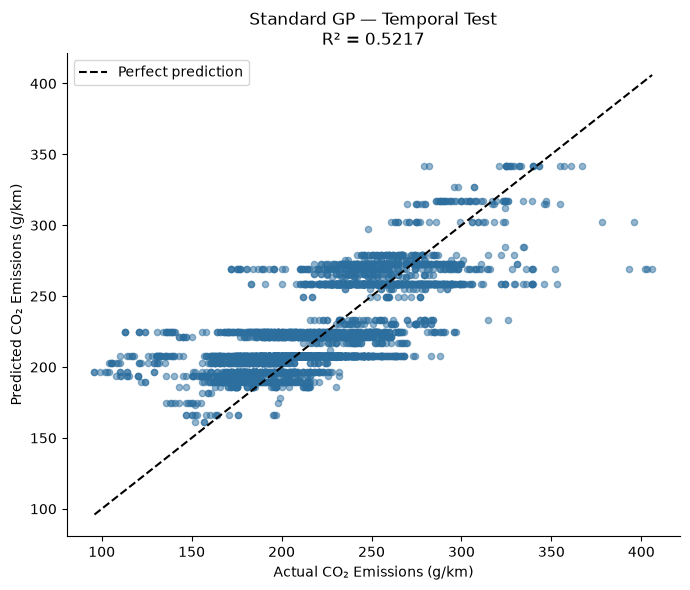

In [101]:
# ============================================================
# 19. PLOT — PREDICTED VS ACTUAL
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    y_new_np,
    y_pred_new,
    alpha=0.5,
    s=20,
    color="#2C6E9E"
)

min_value = min(
    y_new_np.min(),
    y_pred_new.min()
)

max_value = max(
    y_new_np.max(),
    y_pred_new.max()
)

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    "k--",
    linewidth=1.5,
    label="Perfect prediction"
)

ax.set_xlabel(
    "Actual CO₂ Emissions (g/km)"
)

ax.set_ylabel(
    "Predicted CO₂ Emissions (g/km)"
)

ax.set_title(
    f"Standard GP — Temporal Test\n"
    f"R² = {test_r2:.4f}"
)

ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../results/figures/standard_gp_temporal_predicted_actual.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()



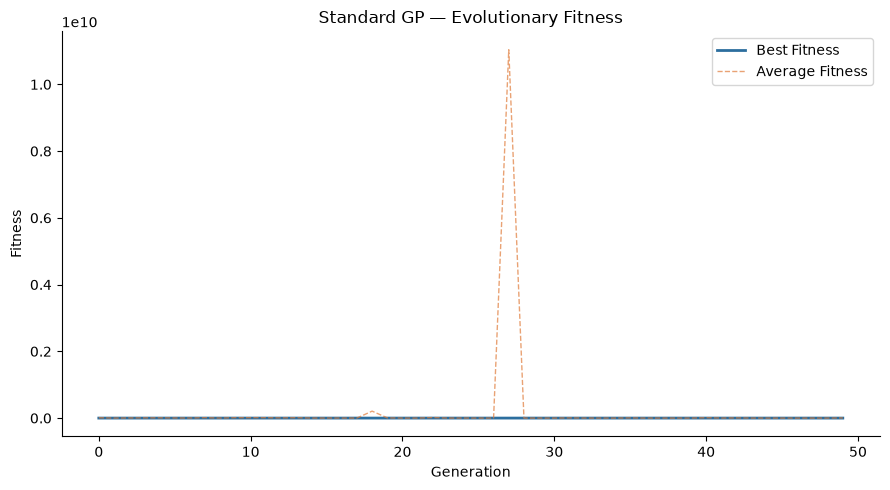

In [102]:
# ============================================================
# 20. PLOT — GP EVOLUTION
# ============================================================

run_df = pd.DataFrame(gp.run_details_)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    run_df["generation"],
    run_df["best_fitness"],
    color="#2C6E9E",
    linewidth=2,
    label="Best Fitness"
)

ax.plot(
    run_df["generation"],
    run_df["average_fitness"],
    color="#E07B39",
    linewidth=1,
    alpha=0.7,
    linestyle="--",
    label="Average Fitness"
)

ax.set_xlabel("Generation")
ax.set_ylabel("Fitness")

ax.set_title(
    "Standard GP — Evolutionary Fitness"
)

ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../results/figures/standard_gp_evolution.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()



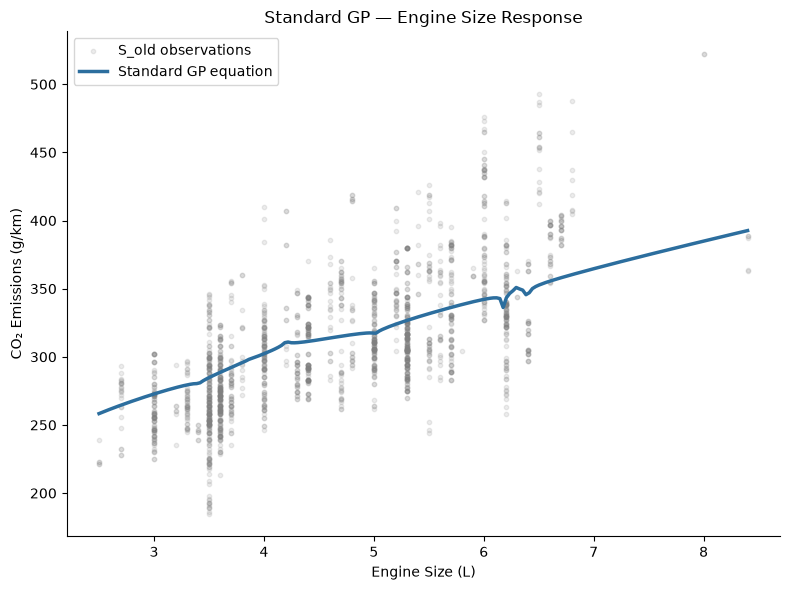

In [103]:
# ============================================================
# 21. ENGINE SIZE RESPONSE
# ============================================================
#
# This is ONLY a visual diagnostic.
#
# Standard GP is NOT constrained to be monotonic.
# DCSR is the model that formally enforces:
#
#       df / d(engine_size) >= 0
# ============================================================

engine_col_idx = GP_FEATURES.index("engine_size")

engine_range = np.linspace(
    X_old_np[:, engine_col_idx].min(),
    X_old_np[:, engine_col_idx].max(),
    200
)

# Hold all other features at their training medians
X_synthetic = np.tile(
    np.median(X_old_np, axis=0),
    (200, 1)
)

X_synthetic[:, engine_col_idx] = engine_range

y_engine = gp.predict(X_synthetic)

invalid_engine = ~np.isfinite(y_engine)

y_engine[invalid_engine] = np.nan

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    X_old_np[:, engine_col_idx],
    y_old_np,
    alpha=0.15,
    s=10,
    color="gray",
    label="S_old observations"
)

ax.plot(
    engine_range,
    y_engine,
    color="#2C6E9E",
    linewidth=2.5,
    label="Standard GP equation"
)

ax.set_xlabel(
    "Engine Size (L)"
)

ax.set_ylabel(
    "CO₂ Emissions (g/km)"
)

ax.set_title(
    "Standard GP — Engine Size Response"
)

ax.legend()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "../results/figures/standard_gp_engine_response.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()



In [104]:
# ============================================================
# 22. SAVE RESULTS
# ============================================================

os.makedirs(
    "../results/tables",
    exist_ok=True
)

os.makedirs(
    "../results/equations",
    exist_ok=True
)

os.makedirs(
    "../results/predictions",
    exist_ok=True
)

os.makedirs(
    "../results/figures",
    exist_ok=True
)



In [105]:
# Save main results
gp_results.to_csv(
    "../results/tables/standard_gp_results.csv",
    index=False
)

# Save CV results
cv_df.to_csv(
    "../results/tables/standard_gp_5fold_cv.csv",
    index=False
)



In [106]:
# Save predictions

prediction_df = pd.DataFrame({

    "Actual_CO2": y_new_np,
    "Predicted_CO2": y_pred_new,
    "Residual": y_new_np - y_pred_new

})

prediction_df.to_csv(
    "../results/predictions/standard_gp_temporal_predictions.csv",
    index=False
)



In [107]:
# Save equation

equation_path = (
    "../results/equations/"
    "standard_gp_equation.txt"
)

with open(
    equation_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "STANDARD GENETIC PROGRAMMING\n"
    )

    f.write(
        "Vehicle CO2 Emission Prediction\n"
    )

    f.write("=" * 60 + "\n\n")

    f.write(
        "Equation:\n"
    )

    f.write(
        equation + "\n\n"
    )

    f.write(
        f"Equation length: "
        f"{gp._program.length_} nodes\n"
    )

    f.write(
        f"Equation depth: "
        f"{gp._program.depth_}\n\n"
    )

    f.write(
        "Training metrics — S_old\n"
    )

    f.write(
        f"R2:   {train_r2:.4f}\n"
    )

    f.write(
        f"RMSE: {train_rmse:.4f}\n"
    )

    f.write(
        f"MAE:  {train_mae:.4f}\n\n"
    )

    f.write(
        "Temporal test metrics — S_new\n"
    )

    f.write(
        f"R2:   {test_r2:.4f}\n"
    )

    f.write(
        f"RMSE: {test_rmse:.4f}\n"
    )

    f.write(
        f"MAE:  {test_mae:.4f}\n\n"
    )

    f.write(
        "5-fold CV\n"
    )

    f.write(
        f"R2: "
        f"{cv_mean_r2:.4f} "
        f"+/- "
        f"{cv_std_r2:.4f}\n"
    )

    f.write(
        f"RMSE: "
        f"{cv_mean_rmse:.4f} "
        f"+/- "
        f"{cv_std_rmse:.4f}\n"
    )

    f.write(
        f"MAE: "
        f"{cv_mean_mae:.4f} "
        f"+/- "
        f"{cv_std_mae:.4f}\n"
    )



In [108]:
# ============================================================
# 23. SAVE DATA FOR DCSR
# ============================================================

np.save(
    "../data/processed/X_old_gp.npy",
    X_old_np
)

np.save(
    "../data/processed/X_new_gp.npy",
    X_new_np
)

np.save(
    "../data/processed/y_old_gp.npy",
    y_old_np
)

np.save(
    "../data/processed/y_new_gp.npy",
    y_new_np
)

pd.Series(
    GP_FEATURES
).to_csv(
    "../data/processed/gp_feature_names.csv",
    index=False,
    header=False
)



In [109]:
# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STANDARD GP COMPLETE")
print("=" * 70)

print("\nEquation:")
print(equation)

print("\nPerformance:")
print(f"Train R²:          {train_r2:.4f}")
print(f"5-fold CV R²:      {cv_mean_r2:.4f} ± {cv_std_r2:.4f}")
print(f"Temporal Test R²:  {test_r2:.4f}")

print("\nError:")
print(f"Temporal RMSE:     {test_rmse:.4f}")
print(f"Temporal MAE:      {test_mae:.4f}")

print("\nComplexity:")
print(f"Equation length:   {gp._program.length_}")
print(f"Equation depth:    {gp._program.depth_}")

print("\nSaved files:")
print("  standard_gp_results.csv")
print("  standard_gp_5fold_cv.csv")
print("  standard_gp_temporal_predictions.csv")
print("  standard_gp_equation.txt")

print("\nStandard GP finished successfully.")


STANDARD GP COMPLETE

Equation:
mul(mul(sqrt(div(mul(X0, 7.683), sqrt(X0))), add(add(add(mul(-4.630, -6.691), X1), add(X0, X1)), add(log(sub(log(sub(sub(3.442, X0), add(sub(-6.215, -1.281), sub(log(sub(sub(3.442, X0), add(sub(-6.215, -1.281), log(X1)))), add(add(sub(-6.215, -1.281), -0.276), log(sub(mul(1.557, -0.276), sub(3.442, X0)))))))), add(add(sub(-6.215, -1.281), -0.276), log(sub(add(-5.668, X1), sub(3.442, X0)))))), add(-5.668, X1)))), log(sub(sqrt(log(sub(sqrt(log(sub(sqrt(-5.668), add(sqrt(X0), sub(mul(1.557, -0.276), sub(3.442, X0)))))), add(add(sub(-6.215, -1.281), -0.276), log(X1))))), add(sub(-6.215, -1.281), log(X1)))))

Performance:
Train R²:          0.5526
5-fold CV R²:      0.5351 ± 0.0576
Temporal Test R²:  0.5217

Error:
Temporal RMSE:     28.4667
Temporal MAE:      21.6313

Complexity:
Equation length:   108
Equation depth:    14

Saved files:
  standard_gp_results.csv
  standard_gp_5fold_cv.csv
  standard_gp_temporal_predictions.csv
  standard_gp_equation.txt

S